# Notebook 02 — Corpus B: Set-to-Ranking Instances

Converts the flat finding list from Notebook 01 into ranking instances — the actual task the
model is trained and evaluated on.

**Runtime: CPU. 3–5 minutes.** No re-cloning or re-scanning; this re-normalises from the
cached scans.

### Why sets rather than individual findings

Objective 4 evaluates a ranking using Kendall's tau. A model trained to score isolated findings
is doing regression, not ranking, and analysts do not triage findings in isolation — they work
a queue. So the training unit is a set of findings and the target is their ordering.

### What this notebook fixes

| Issue | Cause | Fix |
|---|---|---|
| Admin grants undercounted 7× | extractor matched only JSON policy syntax, missing `Action = "*"` inside `jsonencode` | both forms matched (mcasm ≥ 1.1) |
| Privilege escalation never detected | no escalation primitives encoded | 22 AWS/Azure/GCP primitives added |
| SSVC collapsed to one class | exploitation criteria written for CVEs, which misconfigurations never satisfy | recalibrated: the misconfiguration is the exploit |
| Scores heavily tied | one finding per failed rule, many per resource | resource-level aggregation |
| Results lost on session end | outputs stayed in `/content` | mirrored to Drive as produced |


## 1 · Setup


In [3]:
!pip -q install "pydantic>=2.0" pyarrow 2>&1 | tail -2

from pathlib import Path
from datetime import datetime, timezone
import collections, json, shutil, sys, zipfile
import numpy as np, pandas as pd

BASE = Path("/content/mcasm_project"); BASE.mkdir(parents=True, exist_ok=True)

for name in ("mcasm_corpus_stage1.zip", "mcasm.zip"):
    p = Path(f"/content/{name}")
    if p.exists():
        with zipfile.ZipFile(p) as z: z.extractall(BASE)
        print(f"{name:28} extracted")
    else:
        print(f"{name:28} NOT FOUND — upload it via the Files pane")

sys.path.insert(0, str(BASE))
OUT, FIG = BASE/"corpus_b", BASE/"figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

DRIVE = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage2"); DRIVE.mkdir(parents=True, exist_ok=True)
    print("Drive mirror:", DRIVE)
except Exception as e:
    print(f"Drive unavailable ({type(e).__name__})")

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name; dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True) if src.is_dir() else shutil.copy(src, dst)
    except Exception as e: print(f"  mirror failed ({name}): {type(e).__name__}")

mcasm_corpus_stage1.zip      extracted
mcasm.zip                    NOT FOUND — upload it via the Files pane
Mounted at /content/drive
Drive mirror: /content/drive/MyDrive/mcasm_stage2


In [8]:
import shutil, sys, zipfile, subprocess
from pathlib import Path

BASE = Path("/content/mcasm_project"); BASE.mkdir(parents=True, exist_ok=True)

print("=== what's on disk ===")
found = [p for p in Path("/content").rglob("mcasm/__init__.py")]
for p in found: print("  package at:", p.parent)
if not found: print("  none")

pkg = Path("/content/mcasm.zip")
print(f"\nmcasm.zip present: {pkg.exists()}"
      + (f"  ({pkg.stat().st_size/1024:.0f} KB)" if pkg.exists() else ""))

if not pkg.exists():
    from google.colab import files
    print("\nUpload mcasm.zip now:")
    files.upload()

assert pkg.exists(), "mcasm.zip still missing"

with zipfile.ZipFile(pkg) as z:
    names = z.namelist()
    print("\nzip contains:", sorted({n.split('/')[1] for n in names
                                    if n.startswith('mcasm/') and n.count('/') > 1}))
    z.extractall(BASE)

init = BASE/"mcasm/__init__.py"
build = BASE/"mcasm/corpus/build_b.py"
print(f"\nafter extract:")
print(f"  {init}  exists={init.exists()}")
print(f"  {build}  exists={build.exists()}")
assert init.exists(), f"extract failed — no __init__.py at {init}"
assert build.exists(), "corpus/build_b.py missing — this is an old mcasm.zip, re-download v1.2"

for m in [k for k in list(sys.modules) if k.startswith("mcasm")]: del sys.modules[m]
while str(BASE) in sys.path: sys.path.remove(str(BASE))
sys.path.insert(0, str(BASE))

import mcasm
from mcasm.normalise.checkov_map import normalise_file
from mcasm.rank.baselines import composite_reference_score, ssvc_classify, generate_justification
from mcasm.corpus.build_b import aggregate_by_resource, build_corpus_b

print(f"\nmcasm {mcasm.__version__} loaded from {mcasm.__file__}")
assert mcasm.__version__ >= "1.2", f"got {mcasm.__version__}, need 1.2+"
print("all imports OK")

=== what's on disk ===
  none

mcasm.zip present: True  (28 KB)

zip contains: ['corpus', 'enrich', 'eval', 'normalise', 'rank', 'schema']

after extract:
  /content/mcasm_project/mcasm/__init__.py  exists=True
  /content/mcasm_project/mcasm/corpus/build_b.py  exists=True

mcasm 1.2.0 loaded from /content/mcasm_project/mcasm/__init__.py
all imports OK


## 2 · Locate the cached scans

Searches anywhere under `/content` so the notebook works regardless of how the Stage 1 archive
was extracted, and fails loudly rather than silently producing an empty corpus.


In [9]:
cands = [p for p in Path("/content").rglob("*.json")
         if p.parent.name == "scans" and p.stat().st_size > 1000]
if not cands:
    raise FileNotFoundError(
        "No Checkov scans found under /content.\n"
        "Upload mcasm_corpus_stage1.zip and re-run the setup cell.")
SCANS = cands[0].parent
print("scans at:", SCANS, f"({len(cands)} files)\n")

findings = []
for f in sorted(SCANS.glob("*.json")):
    got = list(normalise_file(f))
    findings += got
    print(f"{f.stem:20} {len(got):5}")
print(f"\nTOTAL: {len(findings)}")
assert findings, "scans found but produced no findings — were they run with --compact?"

scans at: /content/mcasm_project/scans (16 files)

awsgoat                215
azuregoat               37
cnappgoat                0
gcpgoat                 43
iam_vulnerable         269
terragoat_aws          215
terragoat_azure        174
terragoat_gcp           56

TOTAL: 1009


### Effect of the extractor fixes


In [10]:
checks = [
 ("internet_reachable", lambda x: x.exposure.internet_reachable),
 ("no auth required",   lambda x: not x.exposure.auth_required),
 ("hardcoded_secret",   lambda x: x.data.hardcoded_secret),
 ("admin privilege",    lambda x: x.identity.privilege_level == "admin"),
 ("wildcard_actions",   lambda x: x.identity.wildcard_actions),
 ("wildcard_principals",lambda x: x.identity.wildcard_principals),
 ("privesc paths > 0",  lambda x: x.identity.privesc_path_count > 0),
 ("cross_account",      lambda x: x.blast_radius.cross_account_trust),
 ("shared_infra",       lambda x: x.blast_radius.is_shared_infrastructure),
]
dens = pd.DataFrame([{"signal":n, "findings":sum(fn(x) for x in findings),
                      "pct":round(100*sum(fn(x) for x in findings)/len(findings),1)}
                     for n, fn in checks]).sort_values("findings", ascending=False)
display(dens.set_index("signal"))

,findings,pct
signal,,
privesc paths > 0,112,11.1
internet_reachable,105,10.4
hardcoded_secret,81,8.0
admin privilege,74,7.3
wildcard_actions,63,6.2
shared_infra,58,5.7
no auth required,9,0.9
wildcard_principals,7,0.7
cross_account,5,0.5


## 3 · Resource-level aggregation

Scanners emit one finding per failed rule, so a single storage bucket can generate seventeen
findings that an analyst treats as one thing to fix. Aggregating to the resource matches how
triage actually works, concentrates the risk signal, and reduces the score ties that weaken
Kendall's tau.

This is design decision DD-005 and belongs in the design log.


In [11]:
pool = aggregate_by_resource(findings)
print(f"{len(findings)} findings -> {len(pool)} resources")

order = ["Track","Track*","Attend","Act"]
cb = collections.Counter(ssvc_classify(x)["outcome"] for x in findings)
ca = collections.Counter(ssvc_classify(x)["outcome"] for x in pool)
display(pd.DataFrame({"per-finding":[cb.get(k,0) for k in order],
                      "per-resource":[ca.get(k,0) for k in order]}, index=order))

sf = [composite_reference_score(x) for x in findings]
sp = [composite_reference_score(x) for x in pool]
vf, vp = collections.Counter(sf), collections.Counter(sp)
display(pd.DataFrame({
 "distinct CRS values":[len(vf), len(vp)],
 "largest tie group":[vf.most_common(1)[0][1], vp.most_common(1)[0][1]],
 "largest tie %":[round(100*vf.most_common(1)[0][1]/len(sf),1),
                  round(100*vp.most_common(1)[0][1]/len(sp),1)],
}, index=["per-finding","per-resource"]))

1009 findings -> 340 resources


,per-finding,per-resource
Track,643,229
Track*,236,77
Attend,130,34
Act,0,0


,distinct CRS values,largest tie group,largest tie %
per-finding,49,201,19.9
per-resource,49,71,20.9


### On the empty `Act` class

`Act` requires active exploitation, automatability, total impact and non-low mission impact
simultaneously. Static IaC analysis rarely satisfies all four, so this corpus is effectively a
three-class ordinal problem. State that plainly in the thesis — three well-populated classes
are more useful than four where one holds a handful of items.

Graph enrichment across resources, or live runtime discovery, would populate it. Both are
future work.


## 4 · Build the ranking instances


In [12]:
N_INSTANCES, SEED = 1500, 42
records = build_corpus_b(findings, n_instances=N_INSTANCES, seed=SEED, aggregate=True)

sizes = [r["n_findings"] for r in records]
print(f"instances : {len(records)}")
print(f"by split  : {dict(collections.Counter(r['split'] for r in records))}")
print(f"set size  : mean {np.mean(sizes):.1f}  min {min(sizes)}  max {max(sizes)}")
print(f"multi-provider instances: {sum(len(r['providers'])>1 for r in records)} / {len(records)}")

instances : 1500
by split  : {'train': 1200, 'validation': 150, 'test': 150}
set size  : mean 12.1  min 8  max 16
multi-provider instances: 1422 / 1500


## 5 · Integrity checks

All must pass. A leak here silently inflates every downstream metric, and the model would
appear to generalise when it had simply memorised.


In [13]:
seen, leaks = {}, 0
for r in records:
    for fid in r["input_order"]:
        if fid in seen and seen[fid] != r["split"]: leaks += 1
        seen[fid] = r["split"]

integrity = {
 "instances_nonzero": len(records) > 0,
 "no_resource_leakage": leaks == 0,
 "all_three_splits": set(r["split"] for r in records) == {"train","validation","test"},
 "targets_complete": all(len(r["target"]["ranking"]) == r["n_findings"] for r in records),
 "ranking_ids_match_input": all(set(r["target"]["ranking"]) == set(r["input_order"]) for r in records),
 "input_order_shuffled": sum(r["target"]["ranking"] == r["input_order"] for r in records) < 0.05*len(records),
 "messages_wellformed": all(len(r["messages"])==3 and r["messages"][-1]["role"]=="assistant" for r in records),
 "assistant_valid_json": all(isinstance(json.loads(r["messages"][-1]["content"]), dict) for r in records),
}
display(pd.Series(integrity, name="passed").to_frame())
assert all(integrity.values()), "integrity failure — do not proceed to training"
print("\nALL CHECKS PASSED")

,passed
instances_nonzero,True
no_resource_leakage,True
all_three_splits,True
targets_complete,True
ranking_ids_match_input,True
input_order_shuffled,True
messages_wellformed,True
assistant_valid_json,True



ALL CHECKS PASSED


## 6 · Token budget


In [14]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")
    L = np.array([len(tok(r["messages"][1]["content"]+r["messages"][2]["content"])["input_ids"])
                  for r in records[:300]])
    print(f"tokens  mean {L.mean():.0f}  p50 {np.percentile(L,50):.0f}  "
          f"p95 {np.percentile(L,95):.0f}  max {L.max()}")
    print(f"suggested max_seq_length = {int(2**np.ceil(np.log2(np.percentile(L,99))))}")
except Exception as e:
    ch = np.array([len(r["messages"][1]["content"])+len(r["messages"][2]["content"]) for r in records])
    print(f"tokenizer unavailable ({type(e).__name__})")
    print(f"chars p95 {np.percentile(ch,95):.0f} -> approx {np.percentile(ch,95)/3.8:.0f} tokens")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

tokens  mean 4786  p50 4752  p95 6271  max 6463
suggested max_seq_length = 8192


## 7 · Figures


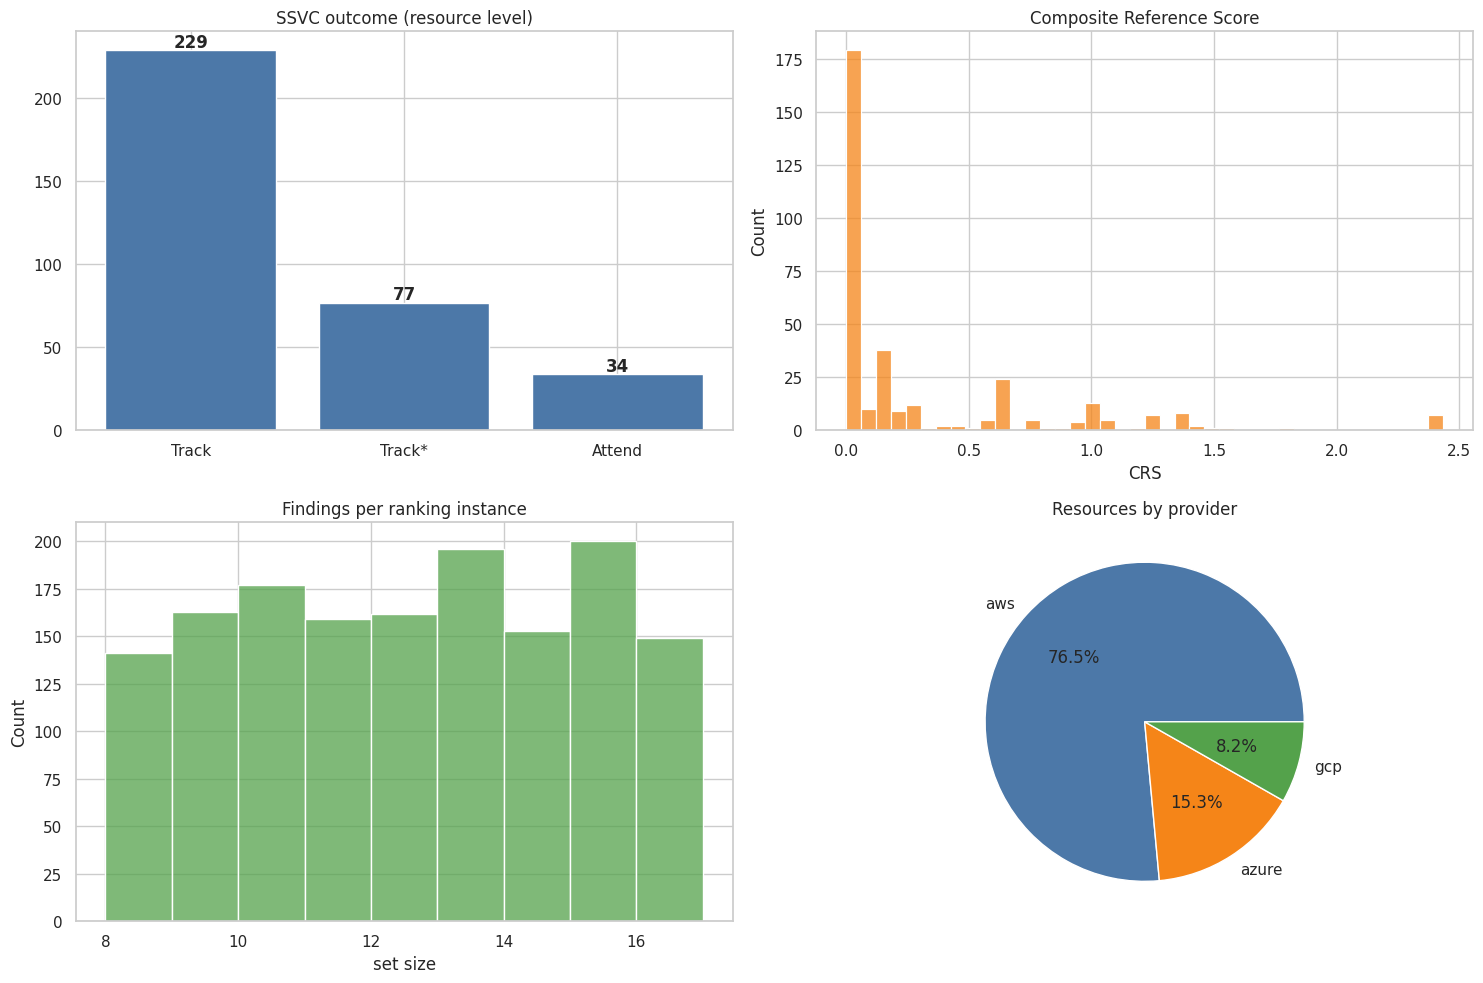

In [15]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
present = [o for o in order if ca.get(o,0)]
ax[0,0].bar(present, [ca.get(o,0) for o in present], color="#4C78A8")
for i,o in enumerate(present): ax[0,0].text(i, ca[o]+2, str(ca[o]), ha="center", fontweight="bold")
ax[0,0].set_title("SSVC outcome (resource level)")

sns.histplot(sp, bins=40, ax=ax[0,1], color="#F58518")
ax[0,1].set_title("Composite Reference Score"); ax[0,1].set_xlabel("CRS")

sns.histplot(sizes, bins=range(min(sizes), max(sizes)+2), ax=ax[1,0], color="#54A24B")
ax[1,0].set_title("Findings per ranking instance"); ax[1,0].set_xlabel("set size")

pv = collections.Counter(x.provider.value for x in pool)
ax[1,1].pie(pv.values(), labels=pv.keys(), autopct="%1.1f%%",
            colors=["#4C78A8","#F58518","#54A24B"])
ax[1,1].set_title("Resources by provider")

plt.tight_layout(); plt.savefig(FIG/"fig3_corpus_b.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig3_corpus_b.png", "figures/fig3_corpus_b.png")

## 8 · Export


In [16]:
for split in ["train","validation","test"]:
    items = [r for r in records if r["split"] == split]
    with open(OUT/f"{split}.jsonl","w",encoding="utf-8") as fh:
        for r in items: fh.write(json.dumps(r, ensure_ascii=False)+"\n")
    print(f"{split:11} {len(items):5} instances")

with open(OUT/"resource_pool.jsonl","w",encoding="utf-8") as fh:
    for x in pool: fh.write(json.dumps(x.model_dump(mode="json"), ensure_ascii=False)+"\n")

manifest_b = {
 "created_utc": datetime.now(timezone.utc).isoformat(),
 "mcasm_version": mcasm.__version__, "seed": SEED,
 "source_findings": len(findings),
 "resources_after_aggregation": len(pool),
 "instances": len(records),
 "split_counts": dict(collections.Counter(r["split"] for r in records)),
 "ssvc_per_finding": {k: cb.get(k,0) for k in order},
 "ssvc_per_resource": {k: ca.get(k,0) for k in order},
 "feature_density": dens.set_index("signal")["findings"].to_dict(),
 "set_size": {"mean": float(np.mean(sizes)), "min": int(min(sizes)), "max": int(max(sizes))},
 "multi_provider_instances": int(sum(len(r["providers"])>1 for r in records)),
 "tie_structure": {"distinct_crs_resource_level": len(vp),
                   "largest_tie_pct": round(100*vp.most_common(1)[0][1]/len(sp),1)},
 "integrity": integrity,
 "design_decisions": {
   "DD-004":"SSVC exploitation recalibrated for misconfigurations; a misconfiguration requires no exploit code.",
   "DD-005":"Findings aggregated to resource level to match analyst triage and reduce tie concentration.",
   "DD-006":"Splits assigned by resource hash so no resource appears in more than one split.",
 },
 "limitations":[
   "SSVC Act class is empty; treat as a three-class ordinal task until graph enrichment or live discovery is added.",
   "Gold rankings are rule-derived. Expert annotation is the reference standard for reported results.",
   "GCP remains under-represented; report per-provider metrics separately.",
 ],
}
(OUT/"manifest_b.json").write_text(json.dumps(manifest_b, indent=2, default=str))
print(json.dumps({k:v for k,v in manifest_b.items() if k != "integrity"}, indent=2, default=str))

train        1200 instances
validation    150 instances
test          150 instances
{
  "created_utc": "2026-08-03T09:14:19.440722+00:00",
  "mcasm_version": "1.2.0",
  "seed": 42,
  "source_findings": 1009,
  "resources_after_aggregation": 340,
  "instances": 1500,
  "split_counts": {
    "train": 1200,
    "validation": 150,
    "test": 150
  },
  "ssvc_per_finding": {
    "Track": 643,
    "Track*": 236,
    "Attend": 130,
    "Act": 0
  },
  "ssvc_per_resource": {
    "Track": 229,
    "Track*": 77,
    "Attend": 34,
    "Act": 0
  },
  "feature_density": {
    "privesc paths > 0": 112,
    "internet_reachable": 105,
    "hardcoded_secret": 81,
    "admin privilege": 74,
    "wildcard_actions": 63,
    "shared_infra": 58,
    "no auth required": 9,
    "wildcard_principals": 7,
    "cross_account": 5
  },
  "set_size": {
    "mean": 12.088,
    "min": 8,
    "max": 16
  },
  "multi_provider_instances": 1422,
  "tie_structure": {
    "distinct_crs_resource_level": 49,
    "largest_t

In [17]:
mirror(OUT, "corpus_b")
arc = shutil.make_archive("/content/mcasm_corpus_b", "zip", OUT)
mirror(arc, "mcasm_corpus_b.zip")
print(f"\narchive: {Path(arc).stat().st_size/1024**2:.1f} MiB")
if DRIVE: print(f"mirrored to {DRIVE}")

from google.colab import files
try: files.download(arc)
except Exception: print("browser download failed — retrieve from Drive")


archive: 2.5 MiB
mirrored to /content/drive/MyDrive/mcasm_stage2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9 · Sanity check

Read one instance the way an analyst would. If the top of the ordering is not clearly more
urgent than the bottom, fix the extractors before training anything.


In [18]:
r = [x for x in records if x["split"]=="test"][0]
lookup = {f["id"]: f for f in r["findings"]}
print(f"instance {r['instance_id']} · {r['n_findings']} findings · {r['providers']}\n")
for rank, fid in enumerate(r["target"]["ranking"], 1):
    f = lookup[fid]
    print(f"{rank:2}. [{r['target']['ssvc'][fid]:7}] CRS={r['crs'][fid]:5.2f}  {f['resource'][:52]}")
    print(f"     exposed={f['exposure']['internet_reachable']} "
          f"priv={f['identity']['privilege_level']} "
          f"privesc={f['identity']['privesc_paths']} "
          f"data={f['data']['sensitivity']}")

instance test_00000 · 12 findings · ['aws', 'azure', 'gcp']

 1. [Attend ] CRS= 0.25  module.privesc-paths.aws_iam_policy.privesc-codeBuil
     exposed=False priv=none privesc=2 data=none
 2. [Track* ] CRS= 1.41  aws_security_group.database-security-group
     exposed=True priv=none privesc=0 data=none
 3. [Track* ] CRS= 1.25  aws_iam_policy.privesc-high-priv-sagemaker-policy
     exposed=False priv=admin privesc=0 data=none
 4. [Track  ] CRS= 0.15  aws_kms_key.logs_key
     exposed=False priv=none privesc=0 data=none
 5. [Track  ] CRS= 0.06  module.privesc-paths.aws_iam_user_policy_attachment.
     exposed=False priv=none privesc=0 data=none
 6. [Track  ] CRS= 0.03  aws_lambda_function.react_lambda_app
     exposed=False priv=none privesc=0 data=none
 7. [Track  ] CRS= 0.03  azurerm_storage_container.storage_container_vm
     exposed=False priv=none privesc=0 data=none
 8. [Track  ] CRS= 0.03  azurerm_storage_container.storage_container_dev
     exposed=False priv=none privesc=0 data=

---

**Next:** `03_baselines_and_model_selection.ipynb`.

Send forward: `mcasm_corpus_b.zip` (also on Drive at `MyDrive/mcasm_stage2/`).
